# AgentState와 context_schema

**이 노트북에서 할 일**

1. 라이브러리 상태 형식 `AgentState`에 칸 하나를 더해, 입력에 넣은 값이 결과까지 남는지 봅니다.
2. 실행할 때 상태 밖으로 넘긴 값(실행 정보)을 도구가 읽고, 결과에는 남지 않는지 봅니다.
3. 실행 정보의 값 하나만 바꿔, 도구 메시지가 어떻게 달라지는지 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 모델 요청은 모두 4번입니다.
7절에서 2번, 8절에서 2번을 보냈습니다.
모델이 도구를 부르지 않으면 요청 수가 달라질 수 있습니다.
요금표로 어림한 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 노트북 안 규정 딕셔너리와 실행 정보를 읽기만 하고, 읽는 파일과 새로 쓰는 파일은 없습니다.
앞에서 배운 함수 다섯은 도구 파일 `runner_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.
모델 응답을 기다리는 시간은 네트워크와 실행 때에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
langgraph 1.2.11, numpy 2.5.3, python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~6절을 읽습니다.
상태 형식과 실행 정보 형식, 도구를 적고 에이전트 그래프의 모양을 보는 자리입니다.
7~9절은 실행 정보를 넘겨 질문을 보내고 값 하나를 바꿔 보는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch21-create-agent`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 파란 상자 agent.invoke 한 번 상태와 context를 따로 넘김에서 칸 둘로 화살표가 갑니다. 왼쪽 칸 상태 결과에 남음에는 초록 상자 입력 상태 질문 하나 ticket_no Q-017, 노란 상자 상태 칸 넷 messages jump_to structured_response ticket_no, 노란 상자 결과 딕셔너리의 키 messages ticket_no와 ticket_no 값 Q-017이 위에서 아래로 이어집니다. 오른쪽 칸 실행 정보 결과에 남지 않음에는 초록 상자 context member_id M-0317 overdue_days 0, 회색 상자 도구 실행 노드가 runtime.context에 담아 도구에 넣어 줌, 노란 상자 도구 메시지 이용자 M-0317 연체가 없어 새 대출을 할 수 있습니다가 위에서 아래로 이어지는 그림](attachment:03-1-상태와-실행-정보가-가는-곳.png)

위에서 아래로 읽습니다.
맨 위 파란 상자는 우리가 적은 invoke 한 줄이고, 왼쪽 칸이 상태, 오른쪽 칸이 실행 정보입니다.
초록 상자는 우리가 넣은 값이고, 노란 상자는 노트북 6·7절에서 출력으로 확인한 값입니다.
오른쪽 칸 회색 상자는 라이브러리가 하는 일로, 설치판 소스로 본 동작입니다.
왼쪽 칸은 결과 딕셔너리의 키까지 이어지고, 오른쪽 칸은 도구 메시지에서 끝납니다.
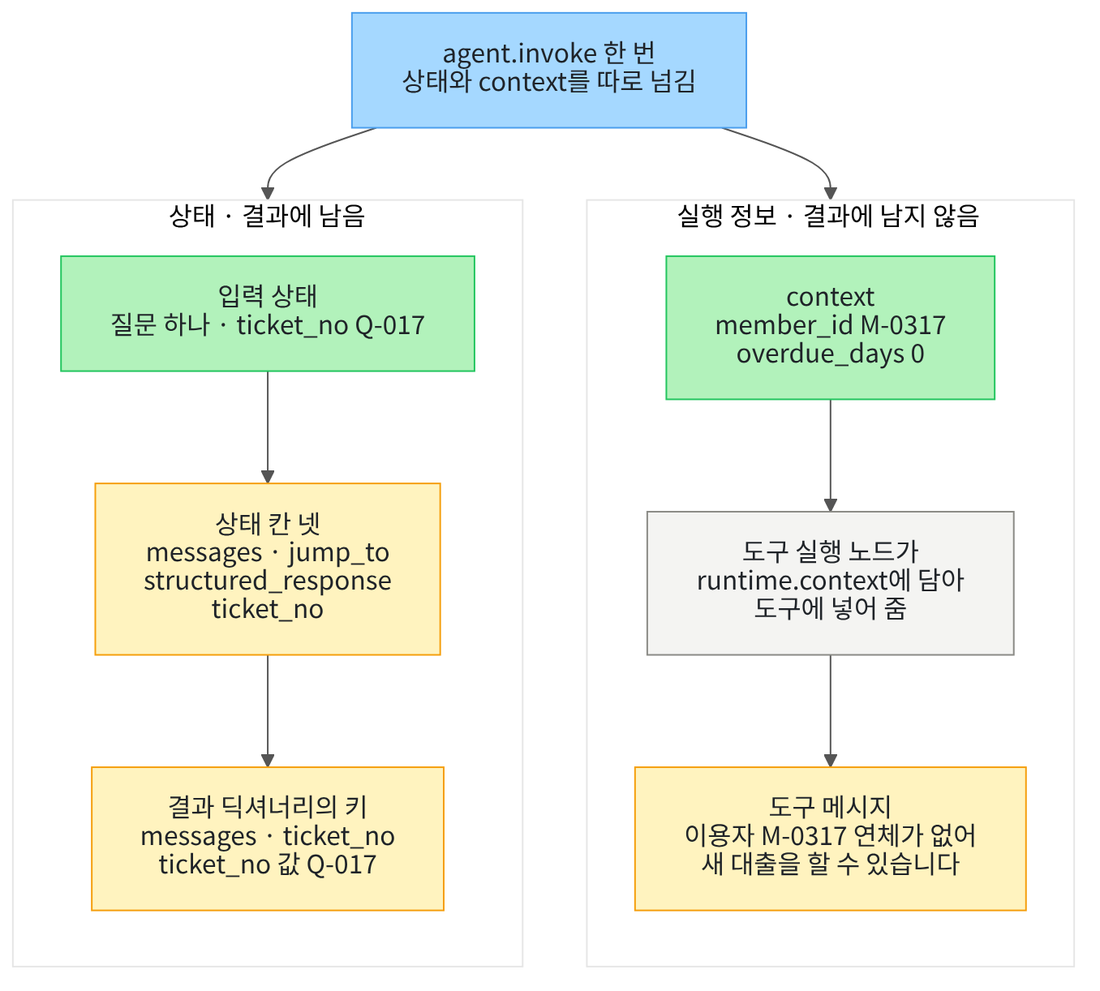

## 1. 준비

01절에서는 함수 `create_agent`로 에이전트 그래프를 만들었습니다.
그때 그래프에 넘긴 값은 질문 메시지 하나뿐이었습니다.
이 절에서는 질문 말고 다른 값을 그래프에 넘기는 두 자리를 봅니다.
하나는 상태에 칸을 더해 넘기는 자리이고, 다른 하나는 상태 밖으로 따로 넘기는 자리입니다.

첫 셀은 패키지 여섯 개를 설치하고 설치된 판 번호를 출력합니다.
도구 파일이 NumPy를 쓰므로, 01절처럼 numpy도 함께 설치합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "langgraph==1.2.11" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langgraph: 1.2.11
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `langgraph: 1.2.11`·`numpy: 2.5.3`·`python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
이름 `TypedDict`는 Ch 13 01절에서 상태 형식을 적을 때 썼습니다.
함수 `convert_to_openai_tool`은 Ch 19 01절에서 도구 명세를 볼 때 썼습니다.
새 이름은 라이브러리 상태 형식 `AgentState`와 도구 매개변수 표시 `ToolRuntime` 둘입니다.

In [2]:
# 상태 형식과 실행 정보 형식을 적을 이름, 에이전트와 도구를 만드는 이름을 가져옵니다
from typing_extensions import TypedDict

from langchain.agents import AgentState, create_agent, middleware
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import ToolRuntime, tool
from langchain_core.utils.function_calling import convert_to_openai_tool

# 앞에서 배운 함수는 도구 파일에서 가져옵니다
from runner_tools import agent_row, estimate_cost, print_branches, show_messages, sum_usage

print("이 절에서 새로 가져온 이름:", "AgentState", "ToolRuntime")

이 절에서 새로 가져온 이름: AgentState ToolRuntime


**결과 읽기** — 출력 줄 `이 절에서 새로 가져온 이름: AgentState ToolRuntime`이 보입니다.
함께 가져온 모듈 `middleware`는 4절에서 클래스 하나를 견줄 때만 씁니다.

앞에서 배운 함수는 `runner_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

함수 `show_messages`는 Ch 19 06절, `sum_usage`는 Ch 19 05절에서 배웠습니다.
함수 `estimate_cost`는 Ch 6 06절, `agent_row`는 01절 10절에서 배웠습니다.
함수 `print_branches`는 02절 6절에서 처음 적은 함수입니다.
이 절부터 다시 쓰므로, 본문을 글자 그대로 도구 파일에 옮겼습니다.

## 2. 키와 모델 준비

모델은 01절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.
이렇게 만든 모델 객체를 이 절의 에이전트 그래프에 넘깁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 쓰는 답 글이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 이 모델로 실행한 결과입니다.

## 3. 규정 자료와 01절 도구

이 절도 01절의 자료실 규정 셋을 씁니다.
5절에서 만드는 도구가 이 딕셔너리의 연체 규정 글을 읽기 때문입니다.
다음 셀은 01절 3절 셀과 글자까지 같은 코드입니다.

In [5]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
5절 도구는 이 가운데 키 `연체`의 글을 읽습니다.

다음 셀도 01절 3절의 도구 셀과 글자까지 같은 코드입니다.
이 절의 에이전트 그래프에는 넣지 않고, 5절에서 도구 명세를 견줄 때만 씁니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(이 오류를 그래프 안에서 다루는 법은 Ch 20 02절에서 보았습니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
매개변수 `topic`은 01절에서 모델이 도구 호출 요청의 인자로 채운 값이었습니다.

## 4. 상태 칸 하나 더하기

01절 5절에서 에이전트 그래프의 상태 칸은 `messages`·`jump_to`·`structured_response` 셋이었습니다.
이 칸 셋을 적은 상태 형식이 라이브러리 LangChain의 `AgentState`입니다.
Ch 13 04절 상태 형식처럼, 메시지 칸에 메시지 리듀서를 적은 `TypedDict`입니다.

Ch 20 01절에서는 우리가 만든 상태 형식에 `AgentState`라는 이름을 붙였습니다.
이 절에서 가져온 `AgentState`는 이름만 같고, 라이브러리가 주는 다른 상태 형식입니다.
다음 셀은 이 클래스가 Ch 22에서 가져오는 자리의 클래스와 같은지 봅니다.

In [7]:
# 이 절의 AgentState가 Ch 22가 가져오는 자리(langchain.agents.middleware)의 AgentState와 같은 클래스인지 봅니다
same_class = AgentState is middleware.AgentState
print("두 자리의 AgentState가 같은 클래스인가:", same_class)

두 자리의 AgentState가 같은 클래스인가: True


**결과 읽기** — 출력 줄 `두 자리의 AgentState가 같은 클래스인가: True`입니다.
모듈 `langchain.agents`와 `langchain.agents.middleware`는 같은 클래스를 내놓습니다.
Ch 22에서 미들웨어 함수의 표시로 쓰는 `AgentState`도 이 클래스입니다.

상태 형식을 넓힌다는 것은 라이브러리 상태 형식의 칸을 그대로 두고 칸을 더하는 일입니다.
자료실 창구에서 문의마다 번호를 적어 두면, 답을 받은 뒤에도 어느 문의의 답인지 찾을 수 있습니다.
다음 셀은 `AgentState`를 물려받아 문의 번호 칸 `ticket_no`를 더한 상태 형식을 적습니다.

클래스 이름 뒤 괄호에 `AgentState`를 적으면, 그 틀의 칸 셋을 물려받은 상태 형식이 됩니다.
Ch 6 03절에서 괄호에 `BaseModel`을 적은 것과 같은 모양입니다.
칸만 적고 메서드는 넣지 않습니다.

In [8]:
# 라이브러리 상태 형식 AgentState에 칸 하나를 더한 상태 형식을 적습니다(칸만 적고 메서드는 없음)
class LibraryState(AgentState):
    # 문의 번호 칸: 입력에 넣고 결과에서 다시 읽을 값입니다(규칙을 적지 않아 덮어쓰는 칸)
    ticket_no: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `ticket_no`에는 규칙을 적지 않았으므로, Ch 13 02절처럼 새 값이 오면 덮어쓰는 칸입니다.
이 상태 형식은 6절에서 인자 `state_schema`로 넘깁니다.

## 5. 실행 정보와 실행 정보를 읽는 도구

실행 정보(context)는 그래프를 실행할 때 상태 밖으로 따로 넘기는 값입니다.
출입 카드로 이미 확인한 이용자 번호처럼, 질문에 적지 않아도 도구가 알아야 하는 값이 여기에 들어갑니다.
이 노트북에서는 이용자 번호와 연체 일수를 실행 정보로 넘깁니다.

인자 이름은 context이지만, Ch 8 01절의 컨텍스트(모델이 받은 글 전체)와는 다른 값입니다.
설치판 소스(`factory.py` 1450~1454행)로 보면, 모델 요청에 싣는 메시지는 시스템 메시지와 메시지 칸뿐입니다.
실행 정보는 모델 요청에 실리지 않습니다.

다음 셀은 실행 정보의 칸을 적는 실행 정보 형식을 적습니다.
Ch 13 01절 상태 형식과 같은 `TypedDict` 모양이라 새 문법은 없습니다.

In [9]:
# 실행할 때 상태 밖으로 넘길 값(실행 정보)의 칸을 적습니다(Ch 13 상태 형식과 같은 모양)
class MemberContext(TypedDict):
    # 이용자 번호와, 지금까지 연체한 일수입니다
    member_id: str
    overdue_days: int

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸은 `member_id`와 `overdue_days` 둘입니다.
이 형식은 6절에서 인자 `context_schema`로 넘기고, 실행할 때는 이 칸을 키로 한 딕셔너리를 넘깁니다.

다음 셀은 실행 정보를 읽는 도구를 만듭니다.
도구 매개변수에 표시 `ToolRuntime`을 붙이면, 라이브러리가 실행 정보를 담은 객체를 넣어 줍니다.
이 매개변수는 모델이 채우는 인자가 아니고, 이 절에서는 이 표시를 실행 객체 표시라고 부릅니다.
Ch 20 02절의 받을 오류 표시처럼, 라이브러리가 표시를 읽고 하는 일을 정하는 자리입니다.

대괄호 안의 `MemberContext`는 Ch 13 04절 `list[AnyMessage]`처럼 안에 든 값의 형식을 적은 것입니다.
도구 안에서 `runtime.context`는 실행할 때 넘긴 딕셔너리이고, 키로 값을 꺼냅니다.

In [10]:
# 실행 정보에서 이용자 번호와 연체 일수를 읽어, 새 대출을 할 수 있는지 알려 주는 도구를 만듭니다
@tool
def check_my_loan(runtime: ToolRuntime[MemberContext]):
    """자료실 이용자 본인이 지금 새 책을 빌릴 수 있는지 확인합니다."""
    # 실행 정보는 딕셔너리로 넘어오므로 키로 꺼냅니다
    member = runtime.context["member_id"]
    days = runtime.context["overdue_days"]
    if days == 0:
        return "이용자 " + member + ": 연체가 없어 새 대출을 할 수 있습니다."
    # 연체가 있으면 3절 규정 딕셔너리의 연체 규정 글을 붙입니다
    return "이용자 " + member + ": 연체 " + str(days) + "일. " + POLICIES["연체"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 이름은 `check_my_loan`이고, 연체 일수가 0이면 새 대출을 할 수 있다는 글을 내놓습니다.
연체 일수가 0이 아니면 3절 딕셔너리의 연체 규정 글을 붙여 내놓습니다.

표시를 대괄호 없이 `ToolRuntime`만 적어도 값은 똑같이 들어갑니다.
이 판에서는 그때 라이브러리 안에서 Pydantic 경고 두 건이 함께 나와, 대괄호로 형식을 적었습니다.
이 비교는 노트북 밖에서 모델을 부르지 않고 확인했고, 이번 노트북에서는 실행하지 않았습니다.

다음 셀은 Ch 19 01절처럼 두 도구의 입력 형식과 도구 명세를 봅니다.
도구 명세는 모델 요청에 실려, 모델이 도구와 인자를 고를 때 보는 글입니다.

In [11]:
# 두 도구에서 모델이 채울 인자(입력 형식)와, 모델 요청에 실릴 도구 명세의 인자를 나란히 봅니다(Ch 19 01절)
for one_tool in [lookup_policy, check_my_loan]:
    arg_names = list(one_tool.args.keys())
    tool_spec = convert_to_openai_tool(one_tool)
    spec_args = tool_spec["function"]["parameters"]["properties"]
    spec_names = list(spec_args.keys())
    print(one_tool.name, "| 입력 형식의 인자:", arg_names, "| 명세의 인자:", spec_names)

lookup_policy | 입력 형식의 인자: ['topic'] | 명세의 인자: ['topic']
check_my_loan | 입력 형식의 인자: [] | 명세의 인자: []


**결과 읽기** — 출력 줄 `lookup_policy | 입력 형식의 인자: ['topic'] | 명세의 인자: ['topic']`입니다.
출력 줄 `check_my_loan | 입력 형식의 인자: [] | 명세의 인자: []`로, 매개변수 `runtime`은 둘 다에 없습니다.
그래서 모델은 이 도구를 인자 없이 부르게 되고, 값은 라이브러리가 넣어 줍니다.

설치판 소스(`langchain_core/tools/base.py` 331~340행)로 보면, 명세를 만들 때 이런 매개변수를 뺍니다.
도구를 실행할 때 실행 객체를 만들어 넣는 곳은 도구 실행 노드입니다(`tool_node.py` 802~817행).

## 6. 두 형식을 붙인 에이전트 그래프

시스템 메시지 글은 01절 4절 글과 앞 문장이 같고, 뒤 문장만 이 절 도구에 맞게 고쳤습니다.
이 절의 에이전트 그래프에는 도구를 하나만 넣습니다.
모델이 도구를 부르는지를 한 가지로 보기 위해서입니다.

다음 셀은 두 형식을 인자 `state_schema`와 `context_schema`로 넘겨 에이전트 그래프를 만듭니다.

In [12]:
# 도구·상태 형식·실행 정보 형식을 넘겨 에이전트 그래프를 만듭니다(요청은 아직 보내지 않음)
system_text = "교육센터 자료실 안내 도우미입니다. 이용자가 지금 새 책을 빌릴 수 있는지 물으면 check_my_loan 도구로 확인한 결과에 근거해 답하세요."
agent = create_agent(
    model,
    tools=[check_my_loan],
    system_prompt=system_text,
    state_schema=LibraryState,
    context_schema=MemberContext,
)
print("만든 것의 종류:", type(agent).__name__)

만든 것의 종류: CompiledStateGraph


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`로, 01절과 같은 종류의 그래프입니다.
이 줄에서도 모델 요청은 나가지 않습니다.

다음 셀은 두 인자를 빼고 만든 그래프를 하나 더 만들어, 상태 칸을 견줍니다.

In [13]:
# 두 형식을 넘기지 않은 그래프를 하나 더 만들어 상태 칸을 견줍니다(요청은 보내지 않음)
plain_agent = create_agent(model, tools=[check_my_loan], system_prompt=system_text)
print("넘기지 않은 그래프의 상태 칸:", list(plain_agent.builder.channels))
print("넘긴 그래프의 상태 칸:", list(agent.builder.channels))

넘기지 않은 그래프의 상태 칸: ['messages', 'jump_to', 'structured_response']
넘긴 그래프의 상태 칸: ['messages', 'jump_to', 'structured_response', 'ticket_no']


**결과 읽기** — 출력 줄 `넘기지 않은 그래프의 상태 칸: ['messages', 'jump_to', 'structured_response']`는 01절 5절과 같습니다.
출력 줄 `넘긴 그래프의 상태 칸: ['messages', 'jump_to', 'structured_response', 'ticket_no']`에 칸이 하나 더해졌습니다.
실행 정보의 칸 `member_id`·`overdue_days`는 상태 칸이 아니어서 이 목록에 없습니다.
설치판 소스(`factory.py` 1174~1192행)로 보면, 상태 형식은 그래프의 칸이 되고 실행 정보 형식은 따로 적힙니다.

다음 셀은 02절 함수 `print_branches`로 노드와 조건 함수를 봅니다.

In [14]:
# 노드와 조건 함수를 봅니다(02절 6절 함수 print_branches — 도구 파일로 옮김)
print("등록된 노드:", list(agent.builder.nodes))
print_branches(agent)

등록된 노드: ['model', 'tools']
tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model']
model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__']


**결과 읽기** — 출력 줄 `등록된 노드: ['model', 'tools']`는 01절과 같습니다.
출력 줄 `tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model']`도 01절과 같습니다.
출력 줄 `model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__']`도 01절과 같습니다.
상태 칸을 더하고 실행 정보 형식을 넘겨도, 노드와 갈래는 바뀌지 않았습니다.

## 7. 실행 정보를 넘겨 질문 보내기

메서드 `invoke`의 첫 인자는 입력 상태이고, 인자 `context`에 실행 정보를 넘깁니다.
입력 상태에는 질문 메시지와 함께 칸 `ticket_no`의 값을 넣습니다.
실행 전에 예상해 봅니다.
모델이 `check_my_loan`을 인자 없이 부르고, 도구 메시지에 이용자 번호가 들어갈 것입니다.
그러면 모델 요청은 2번이고, 메시지 칸에는 메시지 넷이 남을 것입니다.

In [15]:
# 질문과 문의 번호는 입력 상태로, 이용자 정보는 실행 정보로 나눠 넘깁니다(모델 노드를 지날 때마다 모델 요청 1번)
loan_question = "제가 지금 새 책을 빌릴 수 있나요?"
first_state = {"messages": [HumanMessage(content=loan_question)], "ticket_no": "Q-017"}
first_context = {"member_id": "M-0317", "overdue_days": 0}
first_result = agent.invoke(first_state, context=first_context)
first_keys = list(first_result.keys())
print("결과 딕셔너리의 키:", first_keys)
print("칸 ticket_no의 값:", first_result["ticket_no"])
# 입력에 넣은 상태 칸 값은 그래프가 옮기는 값이라, 실행마다 같아야 합니다
assert first_result["ticket_no"] == first_state["ticket_no"], "칸 ticket_no에는 입력에 넣은 값이 남아야 합니다"

결과 딕셔너리의 키: ['messages', 'ticket_no']
칸 ticket_no의 값: Q-017


**결과 읽기** — 출력 줄 `결과 딕셔너리의 키: ['messages', 'ticket_no']`입니다.
01절 결과의 키는 `messages` 하나였고, 이번에는 더한 칸 `ticket_no`가 함께 나왔습니다.
출력 줄 `칸 ticket_no의 값: Q-017`은 입력에 넣은 값 그대로입니다.
셀 끝 `assert`는 모델이 쓴 글이 아니라, 그래프가 옮긴 이 칸 값에만 걸었습니다.

다음 셀은 메시지 칸을 차례로 출력합니다.

In [16]:
# 메시지 칸을 차례로 출력합니다(Ch 19 06절 함수 show_messages)
print("메시지 칸:")
show_messages(first_result["messages"])

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['check_my_loan']
ToolMessage | 결과 상태: success | 내용: 이용자 M-0317: 연체가 없어 새 대출을 할 수 있습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 `메시지 칸:` 아래 네 줄입니다.
둘째 줄 `AIMessage | 도구 호출 요청: ['check_my_loan']`에서 모델이 이 절 도구를 불렀습니다.
셋째 줄 도구 메시지의 내용은 `이용자 M-0317: 연체가 없어 새 대출을 할 수 있습니다.`입니다.
이 글은 도구 몸통이 실행 정보의 두 값으로 만든 글입니다.
넷째 줄 `AIMessage | 도구 호출 요청: []`에서 요청이 없어 흐름이 끝났습니다.

다음 셀은 첫 응답에서 모델이 도구 호출 요청에 채운 인자를 봅니다.

In [17]:
# 둘째 메시지(첫 응답)에 담긴 도구 호출 요청의 이름과, 모델이 채운 인자를 봅니다
first_response = first_result["messages"][1]
for call in first_response.tool_calls:
    print("도구 이름:", call["name"], "| 인자:", call["args"])

도구 이름: check_my_loan | 인자: {}


**결과 읽기** — 출력 줄 `도구 이름: check_my_loan | 인자: {}`로, 모델은 인자를 하나도 채우지 않았습니다.
이용자 번호는 질문 글에도 인자에도 없었는데, 도구 메시지에는 들어 있었습니다.
라이브러리가 실행 정보를 매개변수 `runtime`에 넣어 주었기 때문입니다.

다음 셀은 실행 정보가 결과 딕셔너리에 남았는지 봅니다.

In [18]:
# 실행 정보의 키가 결과 딕셔너리에 있는지, 도구 메시지에 이용자 번호가 들어 있는지 봅니다
context_keys = list(first_context.keys())
for key in context_keys:
    print(key, "| 결과 딕셔너리에 있는가:", key in first_result)
for message in first_result["messages"]:
    if type(message).__name__ == "ToolMessage":
        print("도구 메시지에 이용자 번호가 있는가:", first_context["member_id"] in message.content)
        # 도구 몸통이 실행 정보로 만든 글이라, 도구가 실행됐다면 이용자 번호가 들어 있어야 합니다
        assert first_context["member_id"] in message.content, "도구 메시지에 실행 정보의 이용자 번호가 있어야 합니다"

member_id | 결과 딕셔너리에 있는가: False
overdue_days | 결과 딕셔너리에 있는가: False
도구 메시지에 이용자 번호가 있는가: True


**결과 읽기** — 출력 줄 `member_id | 결과 딕셔너리에 있는가: False`와 `overdue_days | 결과 딕셔너리에 있는가: False`입니다.
출력 줄 `도구 메시지에 이용자 번호가 있는가: True`입니다.
실행 정보는 도구가 읽었지만, 결과 딕셔너리의 칸으로는 남지 않았습니다.
값이 결과에 보이는 곳은 도구가 만든 글 안뿐이고, 그 글은 메시지 칸에 있습니다.
셀 끝 `assert`는 도구 메시지가 있을 때만, 도구 몸통이 만든 글에 걸었습니다.

다음 셀은 메시지 칸의 마지막 응답을 봅니다.

In [19]:
# 메시지 칸의 마지막 응답을 봅니다(도구 호출 요청 수와 답 글)
last_message = first_result["messages"][-1]
print("마지막 응답의 도구 호출 요청 수:", len(last_message.tool_calls))
print("답 글:")
print(last_message.content)

마지막 응답의 도구 호출 요청 수: 0
답 글:
네, 가능합니다.  
현재 연체가 없어 **새 책을 대출할 수 있습니다**.


**결과 읽기** — 출력 줄 `마지막 응답의 도구 호출 요청 수: 0`입니다.
라벨 줄 `답 글:` 아래가 모델이 도구 메시지를 보고 쓴 답입니다.
소스로 보면 도구 메시지는 메시지 칸에 있어, 둘째 모델 요청에 실렸습니다.

답 글은 모델이 쓴 글이라 실행마다 글자가 달라질 수 있습니다.
이번 실행에서는 도구 메시지대로 새 책을 빌릴 수 있다는 뜻의 글이었습니다.

## 8. 값 바꿔 보기 · 연체 일수 바꾸기

바꿀 값은 실행 정보의 `overdue_days` 하나입니다.
0을 3으로 바꾸고, 질문과 칸 `ticket_no`의 값, 에이전트 그래프는 그대로 둡니다.
실행 전에 예상해 봅니다.
도구 메시지가 연체 규정 글을 붙인 글로 바뀌고, 메시지 수와 모델 요청 수는 7절과 같을 것입니다.

In [20]:
# 바꿀 값: 실행 정보의 연체 일수 하나만 3으로 바꿔 같은 질문을 보냅니다(입력 상태의 값도 그대로)
second_state = {"messages": [HumanMessage(content=loan_question)], "ticket_no": "Q-017"}
second_context = {"member_id": "M-0317", "overdue_days": 3}
second_result = agent.invoke(second_state, context=second_context)
print("칸 ticket_no의 값:", second_result["ticket_no"])
print("메시지 칸:")
show_messages(second_result["messages"])

칸 ticket_no의 값: Q-017
메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['check_my_loan']
ToolMessage | 결과 상태: success | 내용: 이용자 M-0317: 연체 3일. 연체한 일수만큼 새 대출이 제한됩니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `칸 ticket_no의 값: Q-017`은 7절과 같습니다.
라벨 줄 `메시지 칸:` 아래 네 줄의 모양도 7절과 같습니다.
셋째 줄 도구 메시지의 내용은 `이용자 M-0317: 연체 3일. 연체한 일수만큼 새 대출이 제한됩니다.`입니다.
도구 몸통의 `if` 갈래가 실행 정보의 연체 일수로 정해졌습니다.

다음 셀은 바꾼 실행의 마지막 응답을 봅니다.

In [21]:
# 바꾼 실행의 마지막 응답을 봅니다(도구 호출 요청 수와 답 글)
second_last = second_result["messages"][-1]
print("마지막 응답의 도구 호출 요청 수:", len(second_last.tool_calls))
print("답 글:")
print(second_last.content)

마지막 응답의 도구 호출 요청 수: 0
답 글:
지금은 새 책을 빌릴 수 없습니다.  
확인 결과, **연체 3일**이라서 **연체한 일수만큼 새 대출이 제한**됩니다.

즉, **3일 후**에 새 책 대출이 가능합니다.


**결과 읽기** — 출력 줄 `마지막 응답의 도구 호출 요청 수: 0`입니다.
라벨 줄 `답 글:` 아래가 모델이 바뀐 도구 메시지를 보고 쓴 답입니다.

답 글은 실행마다 글자가 달라질 수 있습니다.
이번 실행에서는 지금은 빌릴 수 없다는 뜻의 글이었습니다. 끝 문장의 「3일 후」는 모델이 규정 글에서 끌어낸 말이고, 도구 메시지에는 없는 말입니다.

다음 셀은 01절 10절 함수 `agent_row`로 두 실행을 한 줄씩 적습니다.
함수의 첫 칸 이름은 `질문`이지만, 여기서는 실행 이름을 넣습니다.

In [22]:
# 두 실행의 기록을 한 줄씩 적어 출력합니다(01절 10절 함수 agent_row — 도구 파일)
run_rows = []
run_rows.append(agent_row("연체 0일", first_result))
run_rows.append(agent_row("연체 3일", second_result))
print("실행 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝")
for row in run_rows:
    print(row["질문"], "|", row["모델 요청 수"], "|", row["도구 메시지 수"], "|", row["호출 ID 짝"])
    # 도구 메시지마다 요청 id를 옮겨 적는 것은 코드가 하는 일이라, 짝은 매번 맞아야 합니다
    assert row["호출 ID 짝"], "도구 메시지마다 같은 차례의 요청 id가 옮겨져야 합니다"

실행 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝
연체 0일 | 2 | 1 | True
연체 3일 | 2 | 1 | True


**결과 읽기** — 라벨 줄 아래 두 줄이 `연체 0일 | 2 | 1 | True`와 `연체 3일 | 2 | 1 | True`입니다.
모델 요청 수와 도구 메시지 수는 두 실행이 같았습니다.
달라진 것은 도구 메시지의 글 하나였습니다.
호출 ID 짝은 두 실행 모두 맞았고, 셀의 `assert`로 확인했습니다.

## 9. 사용량과 예상 비용

다음 셀은 Ch 19 05절 함수 `sum_usage`로 두 결과의 요청 수와 토큰을 더합니다.

In [23]:
# 두 결과의 요청 수와 입력·출력 토큰을 더합니다(Ch 19 05절 함수 sum_usage)
first_usage = sum_usage(first_result["messages"])
second_usage = sum_usage(second_result["messages"])
print("연체 0일 사용량:", first_usage)
print("연체 3일 사용량:", second_usage)

연체 0일 사용량: {'requests': 2, 'input_tokens': 426, 'output_tokens': 39}
연체 3일 사용량: {'requests': 2, 'input_tokens': 434, 'output_tokens': 76}


**결과 읽기** — 두 사용량 모두 `'requests': 2`로, 모델 요청은 2번씩이었습니다.
입력 토큰은 연체 0일 `'input_tokens': 426`, 연체 3일 `'input_tokens': 434`입니다.
둘째 요청에 실린 도구 메시지 글이 달라 생긴 차이로 보이지만, 몫을 나눠 세지는 않았습니다.

출력 토큰은 모델이 쓴 글에 따라 실행마다 달라질 수 있습니다.
이번 실행에서는 연체 0일 `'output_tokens': 39`, 연체 3일 `'output_tokens': 76`이었습니다.

다음 셀은 Ch 6 06절 함수 `estimate_cost`로 두 사용량의 예상 비용을 셉니다.
요금은 2026-09-17 요금표의 100만 토큰당 달러입니다.

In [24]:
# 2026-09-17 요금표(100만 토큰당 달러)로 두 결과의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
first_cost = round(estimate_cost(first_usage, input_rate, cached_input_rate, output_rate), 6)
second_cost = round(estimate_cost(second_usage, input_rate, cached_input_rate, output_rate), 6)
print("연체 0일 예상 비용(달러):", first_cost)
print("연체 3일 예상 비용(달러):", second_cost)

연체 0일 예상 비용(달러): 0.000495
연체 3일 예상 비용(달러): 0.000668


**결과 읽기** — 라벨 `연체 0일 예상 비용(달러):`와 `연체 3일 예상 비용(달러):` 뒤 값이 예상 비용입니다.
요금표로 어림한 값이고, 청구 금액이 아닙니다.
사용량에 캐시 입력 칸이 없어, 입력 토큰은 모두 입력 요금으로 셌습니다.

출력 토큰이 실행마다 달라질 수 있어, 이 값도 달라질 수 있습니다.
이번 실행에서는 연체 0일 `0.000495`달러, 연체 3일 `0.000668`달러였습니다.

## 정리

1. 라이브러리 상태 형식 `AgentState`를 물려받아 칸 `ticket_no`를 더하자, 입력에 넣은 값이 결과에 남았습니다.
2. 인자 `context`로 넘긴 실행 정보는 도구 매개변수 `runtime`으로 들어갔고, 결과의 칸으로는 남지 않았습니다.
3. 실행 정보의 연체 일수만 바꾸자 도구 메시지 글이 바뀌었고, 모델 요청은 두 실행 모두 2번이었습니다.

04절에서는 옛 판의 에이전트 함수에서 지금 판 `create_agent`로 옮길 때 무엇이 바뀌는지 봅니다.